# Launching Satellites w/ Quadratic Air Drag: 
A handful of startup companies are looking to revolutionize the space industry by launching satellites from the ground with a huge initial velocity, which will take them to a specified height in the atmosphere before using any sort of rocket propulsion to carry the craft the rest of the way into orbit (see SpinLaunch as an example of this idea in action- https://www.spinlaunch.com/). This method of launching satellites effectively removes the ‘first stage’ of a rocket, which is a majority of the weight and fuel cost in a traditional rocket launch (think about the discussion we just had in Chp 3). If successful, this is will be a huge achievement, but many technical barriers remain before the idea can be fully realized. Imagine now for a moment, that you are part of a team working to develop a space launch system under this paradigm. You are being tasked with estimating the initial velocity of launch needed to achieve a height of 80 km above earth’s surface including realistic effects such as air drag.
Computational Methods: For this problem, I am asking you to use a different approach compared to problem #2, because that solution makes a few assumptions that we’ll want to avoid for a problem of this nature. Instead, let’s model the drag force in exercise using an equation known as the Prandtl expression, which is given by $F(v) = \frac{1}{2}c_w\rho_{air}Av^2$ , where $c_w$ is known as the drag coefficient, $\rho_{air}$ is the density of air, $A$ is the cross-section of the object, and $v$ is the velocity. What
makes this calculation tricky is that the density of air decreases with height in the atmosphere (as
in problem 2, but you will likely want to reference a detailed model of the atmosphere such as
NRLMSISE-00, which is available here: https://www.amentum.io/atmosphere_docs#tag/wam or see https://en.wikipedia.org/wiki/NRLMSISE-00) and also the drag coefficient depends on speed (and example plot is given below showing dependence of Mach number which is the ratio of speed vs. sound speed in medium). These additional dependencies on position and velocity go beyond the simple form $F(v) ∝ v^2$ and make the problem much more tractable using numerical methods. My advice for this exercise is to think about solving the equation using a grid of points (or regions) through the atmosphere and solving the equation where we can assume simple functional forms for $c_w$ and $\rho_{air}$ , and then if needed ‘stitching’ the answers together using common boundary conditions to link one region to the next for where the functional forms of these equations might have changed from one region to the next. Note this approach will require you to think very carefully about boundary conditions and ensuring your solution doesn’t violate assumptions you make about the drag coefficient and air density profile. You will also likely have to produce several trials of this calculation to determine the height achieved, and then do some iterations based on your initial velocity ‘guesses’ to figure out the velocity value corresponding to the desired height in the atmosphere. I’ll note that I don’t consider there to be a ‘correct’ answer to this problem, because I want to give you the freedom to think about the problem with an open mind. You are able to make choices and assumptions in this problem that make the numerics more approachable. But I will say that the better your choices and assumptions are, the more accurate your solution will be. That said, part of the grading will ask you to critically evaluate how ‘reasonable’ some of your choices are. If you have questions or concerns about specific items in this regard, please feel free to ask me.

Since we're talking about a fast-moving, massive object like a rocket, we are definitely in the  regime where 

$$
R_e = \frac{f_{quad}}{f_{lin}} = \frac{\rho_{air}Dv}{\eta} >> 1000
$$

So the quadratic drag dominates. Let's launch the rocket straight up, since that will give us the greatest vertical range. Then the equation of motion is 

$$
ma = F_y = -F(v) - mg \\
\dot{v} = -\frac{1}{m}c(y)v^2 -g(y)
$$

For my calculations, I'll be using the mold of NASA's Mercury Atlas rocket, also known as the Atlas LV-3B. It would be ideal to use a small rocket as it would lose less speed as it travels, but the I was able to find information about the drag coefficient of the Atlas rocket, which is usually not published by manufacurers. The Mercury Atlas is 25.00 meters tall and its body has diameter $D = 3.05m$. It has a mass of $m = 116100kg$. 

The Prandtl expression tells us that $c = \frac{1}{2}c_D\rho_{air}A$. Given the diameter of the rocket, we can find the cross sectional area $A$ easy enough. However, $c_D$ and $\rho_{air}$ are entirely different matters. Both very depending atmospheric conditions and the speed of the speed of the rocket. Seeing as how there are far too many variables and I am lacking far too many wind tunnels to come up with values myself, I'm going to turn to the next best thing: online resources. engineeringtoolbox.com has a table of atmospheric information depending on altitude. This can be used to get values for the density, pressure, and temperature of the air. However, using this tables assumes the air is dry and the temperature is 15 degrees C at sea level. It is not entirely unreasonable to choose to launch near sea level on a dry day at this temperature, but keep track of these assumptions. This data also includes the acceleration due to gravity $g$, which gets weaker as the rocket gets further from the surface of Earth. 

Additionally, the drag coefficient depends on the geometry of the projectile, and is typically formulated as a function of the mach number $M = \frac{v}{u}$, where $u$ is the speed of sound in the medium. $u$ can be calculated as

$$
u = \sqrt{\frac{\gamma RT}{M_m}}
$$

Where $R$ is the ideal gas constant, $M_m$ is the molecular mass of air, and $\gamma$ is the adiabatic index of air. $\gamma$ is also a function of temperature, but values for $\gamma$ can also be found at engineeringtoolbox.com. I couldn't find an exact formula for $c_D$ of a Mercury Atlas, but one resource found data for it and NASA's Saturn V rocket and averaged the two datasets together, producing a model that provides a ballpark estimate of $c_D$ for a typical rocket of similar build. 

| Mach Range | $C_D$ |
| :---: | :---: |
| $M \le 0.6$ | $0.2083333M^2 - 0.25M + 0.46$ |$
| $0.6 < M \le 0.85$ | $1.25M^3 - 2.125M^2 + 1.2M + 0.16$ |

I just realized this isn't making it into the report so there's no real point in listing all of them just check the references if you want to know

# References

Atlas Mercury Specs: http://www.astronautix.com/a/atlaslv-3bmercury.html

Atmospheric Data: https://www.engineeringtoolbox.com/standard-atmosphere-d_604.html

Adiabatic Index: https://www.engineeringtoolbox.com/specific-heat-ratio-d_602.html

Speed of Sound in a Medium: https://phys.libretexts.org/Bookshelves/University_Physics/University_Physics_(OpenStax)/Book:_University_Physics_I_-_Mechanics_Sound_Oscillations_and_Waves_(OpenStax)/17:_Sound/17.03:_Speed_of_Sound

Drag Coefficient reliance on Temperature: http://braeunig.us/space/aerodyn_wip.htm

In [ ]:
import requests
from html_table_parser import HTMLTableParser
import pandas as pd

url = "https://www.engineeringtoolbox.com/standard-atmosphere-d_604.html"
response = requests.get(url)
xhtml = response.text

p = HTMLTableParser()
p.feed(xhtml)

# Turn into a pandas dataframe and simplify column names
df = pd.DataFrame(p.tables[1][1:], columns=p.tables[1][0])
new_columns = ['Altitude (m)', 'Temperature (°C)', 'g (m/s²)', 'Pressure (10⁴ Pa)', 'Density (kg/m³)', 'Viscocity (10^-5 N*s/m²)']
df = df.rename(columns=dict(zip(df.columns, new_columns)))

# Convert columns to floats
for col in df.columns:
    df[col] = df[col].astype(float)

# Convert temp to Kelvin
df['Temperature (°C)'] = df['Temperature (°C)'] + 273.15
df = df.rename(columns={'Temperature (°C)': 'Temperature (K)'})

print(df)
df.to_csv('atmosphere_data.csv', index=False)

    Altitude (m)  Temperature (K)  g (m/s²)  Pressure (10⁴ Pa)  \
0        -1000.0           294.65     9.810          11.390000   
1            0.0           288.15     9.807          10.130000   
2         1000.0           281.65     9.804           8.988000   
3         2000.0           275.15     9.801           7.950000   
4         3000.0           268.66     9.797           7.012000   
5         4000.0           262.17     9.794           6.166000   
6         5000.0           255.68     9.791           5.405000   
7         6000.0           249.19     9.788           4.722000   
8         7000.0           242.70     9.785           4.111000   
9         8000.0           236.21     9.782           3.565000   
10        9000.0           229.73     9.779           3.080000   
11       10000.0           223.25     9.776           2.650000   
12       15000.0           216.65     9.761           1.211000   
13       20000.0           216.65     9.745           0.552900   
14       2

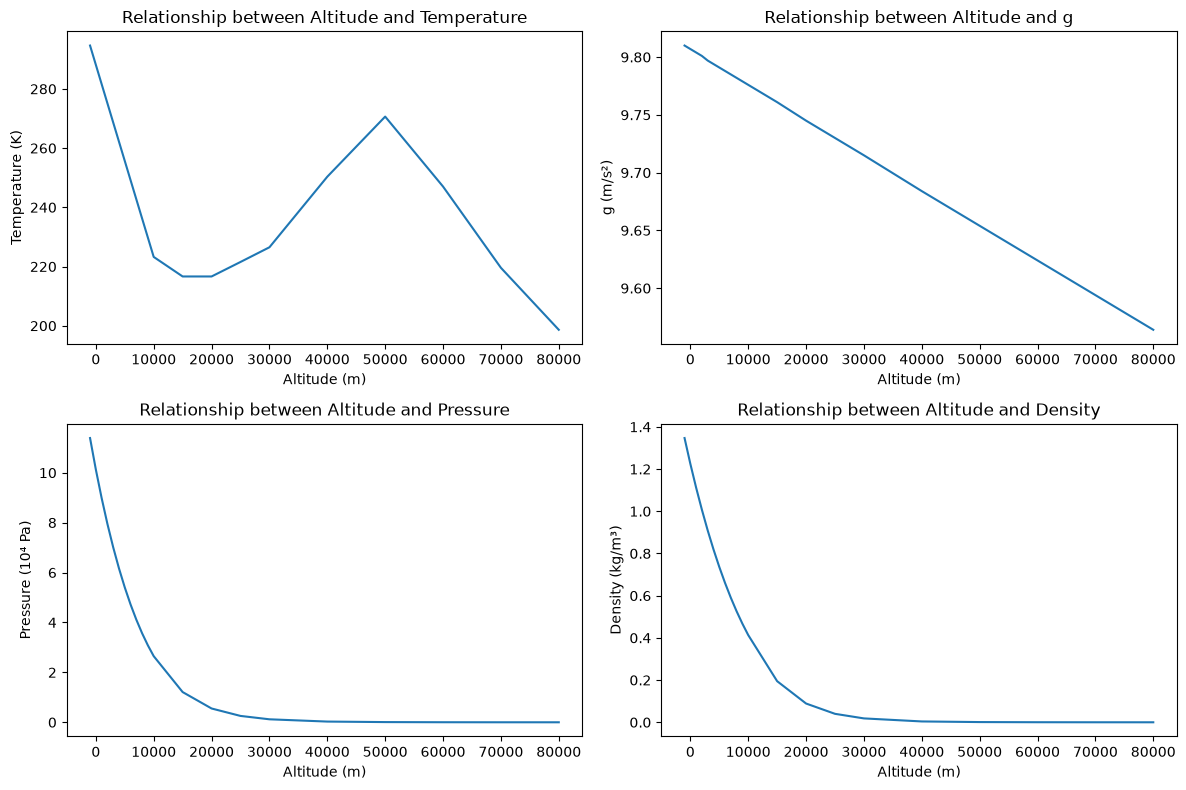

In [ ]:
# Plot relationships to altitude
import matplotlib.pyplot as plt

altitude = df['Altitude (m)']
dependent_vars = df.drop(columns=['Altitude (m)', 'Viscocity (10^-5 N*s/m²)'])  # Exclude altitude and viscosity for plotting

plt.figure(figsize=(12, 8))
for i, col in enumerate(dependent_vars.columns):
    plt.subplot(2, 2, i + 1)
    plt.plot(altitude, dependent_vars[col])
    plt.title(f"Relationship between Altitude and {col.split()[0]}")
    plt.xlabel('Altitude (m)')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

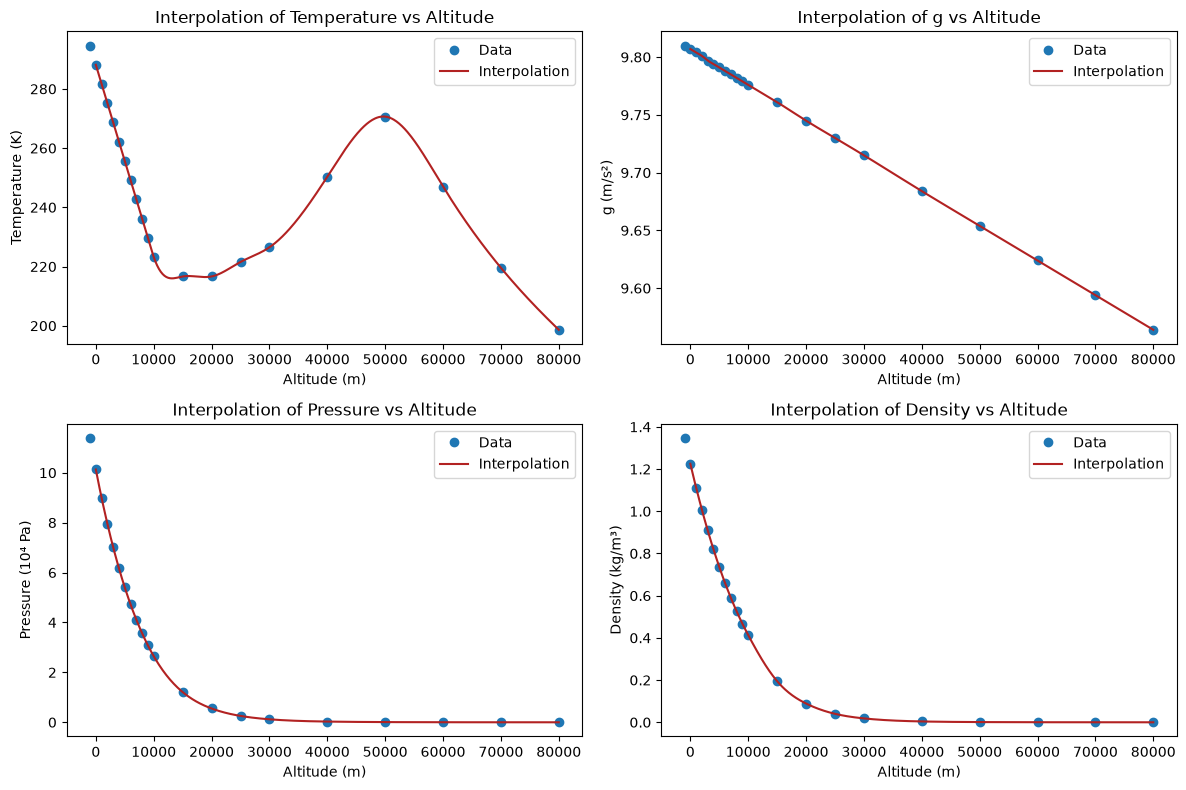

In [ ]:
# Modeling relationships with altitude using interpolation
from scipy.interpolate import make_interp_spline
import numpy as np

# Create interpolation functions for each dependent variable
interpolation_funcs = {}
for col in dependent_vars.columns:
    interpolation_funcs[col] = make_interp_spline(altitude, dependent_vars[col])

altitude_vals = np.linspace(0, 80000, 500)  

plt.figure(figsize=(12, 8))
for i, col in enumerate(dependent_vars.columns):
    plt.subplot(2, 2, i + 1)
    plt.plot(altitude, dependent_vars[col], 'o', label='Data')
    plt.plot(
        altitude_vals,
        interpolation_funcs[col](altitude_vals),
        '-',
        label='Interpolation',
        color='firebrick')
    
    plt.title(f"Interpolation of {col.split()[0]} vs Altitude")
    plt.xlabel('Altitude (m)')
    plt.ylabel(col)
    plt.legend()
plt.tight_layout()
plt.show()

# Remove units because copy-pasting gets old fast
funcs = {key.split()[0]: val for key, val in interpolation_funcs.items()} 

# Cutoff values after 80 km (air density goes to zero so T hardly matters at this point)
for col in funcs.keys():
    funcs[col] = lambda y, func=funcs[col]: func(y) if y <= 80000 else func(80000)

# g doesn't quite drop off as quickly, but we can still define it analytically
G = 6.67430e-11  # m³/kg/s²
M = 5.972e24  # kg
R_earth = 6.371e6  # m

funcs['g'] = lambda y: G * M / (R_earth + y)**2

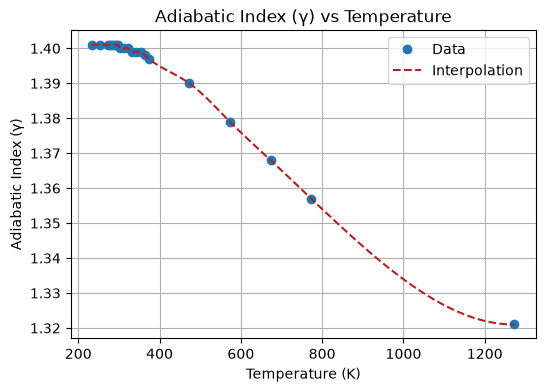

In [94]:
# Also grab adiabatic index (gamma)
url = "https://www.engineeringtoolbox.com/specific-heat-ratio-d_602.html"
response = requests.get(url)
xhtml = response.text

p = HTMLTableParser()
p.feed(xhtml)

# Turn into a pandas dataframe and simplify column names
df_gamma = pd.DataFrame(p.tables[1][1:], columns=p.tables[1][0])
for col in df_gamma.columns:
    df_gamma[col] = df_gamma[col].astype(float)

new_columns_gamma = ['Temperature (K)', 'Adiabatic Index (γ)']
df_gamma = df_gamma.rename(columns=dict(zip(df_gamma.columns, new_columns_gamma)))
df_gamma['Temperature (K)'] = df_gamma['Temperature (K)'] + 273.15  

# Interpolate adiabatic index (gamma) as a function of temperature
f_gamma = make_interp_spline(df_gamma['Temperature (K)'], df_gamma['Adiabatic Index (γ)'])
T_vals = np.linspace(df_gamma['Temperature (K)'].min(), df_gamma['Temperature (K)'].max(), 100)


plt.figure(figsize=(6,4))
plt.plot(df_gamma['Temperature (K)'], df_gamma['Adiabatic Index (γ)'], label='Data', marker='o', linestyle='')
plt.plot(T_vals, f_gamma(T_vals), '--', label='Interpolation', color='firebrick')
plt.title("Adiabatic Index (γ) vs Temperature")
plt.xlabel('Temperature (K)')
plt.ylabel('Adiabatic Index (γ)')
plt.grid()
plt.legend()
plt.show()

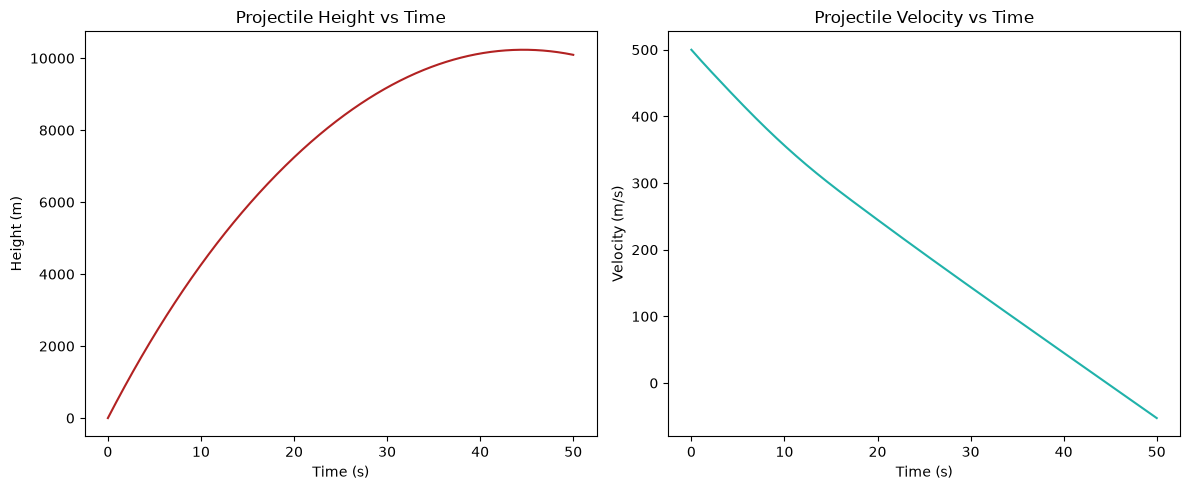

In [108]:
import numpy as np
from scipy.integrate import solve_ivp

# Constants 
D = 3.05
m = 116100
R = 8.3145
M_m = 0.0289644
R_specific = R / M_m

def v_sound(y):
    # If T is outside 
    T = funcs['Temperature'](y)
    gamma = f_gamma(T)
    return np.sqrt(gamma * R_specific * T)

def mach_number(y, v):
    return v / v_sound(y)

def drag_coeff(y, v):
    M = mach_number(y, v)

    if M <= 0.6:
        return 0.208333*M**2 - 0.25*M + 0.46

    elif 0.6 < M <= 0.8:
        return 1.25*M**3 - 2.125*M**2 + 1.2*M + 0.16

    elif 0.8 < M <= 0.95:
        return 10.37037*M**3 - 22.88889*M**2 + 16.91111*M - 3.78963

    elif 0.95 < M <= 1.05:
        return -30*M**3 + 88.5*M**2 - 85.425*M + 27.51375

    elif 1.05 < M <= 1.15:
        return -20*M**3 + 60*M**2 - 58.65*M + 19.245

    elif 1.15 < M <= 1.3:
        return 11.85185*M**3 - 44.88889*M**2 + 56.22222*M - 22.58519

    elif 1.3 < M <= 2:
        return -0.04373178*M**3 + 0.3236152*M**2 - 1.1019679*M + 1.554752

    elif 2 < M <= 3.25:
        return 0.01024*M**3 - 0.00864*M**2 - 0.33832*M + 1.08928

    elif 3.25 < M <= 4.5:
        return -0.01408*M**3 + 0.19168*M**2 - 0.86976*M + 1.53544

    elif M > 4.5:
        return 0.22

    else:
        raise ValueError("Mach number is out of the expected range.")

def c_func(y, v):
    rho = funcs['Density'](y)
    c_D = drag_coeff(y, v)
    return 0.5 * c_D * rho * D**2

def solve_rocket_motion(v0, t_max=50):
    # Solve the differential equation
    def vp(y, v):
        g = funcs['g'](y)
        c = c_func(y, v)
        return -g - (c/m)*v**2

    def state(t, z):
        y, v = z
        return [v, vp(y, v)]

    t_span = (0, t_max)
    t_eval = np.linspace(0, t_max, 1000)

    z0 = [0, v0]

    # Want to find when the rocket reaches 80 km altitude
    def event(t, z):
        return z[0] - 80000
    event.terminal = True

    sol = solve_ivp(
        state,
        t_span,
        z0,
        t_eval=t_eval,
        events=event
    )

    t = sol.t
    y = sol.y[0]
    v = sol.y[1]

    if sol.status == 1:
        print(f"Rocket reached 80 km altitude at t = {sol.t_events[0][0]:.2f} s")

    colors = ['firebrick', 'lightseagreen']

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(t, y, color=colors[0])
    plt.title("Projectile Height vs Time")
    plt.xlabel("Time (s)")
    plt.ylabel("Height (m)")

    plt.subplot(1, 2, 2)
    plt.plot(t, v, color=colors[1])
    plt.title("Projectile Velocity vs Time")
    plt.xlabel("Time (s)")
    plt.ylabel("Velocity (m/s)")
    plt.tight_layout()

    plt.show()

solve_rocket_motion(v0=500, t_max=50)

# Put stopping conditions so interpolation doesn't become extrapolation dumbass